# Figure 3, Panel C

Violin plots showing distribution of accessibility log2FC due to BAFinh (BRM014) or ACBI1 at primed and active enhancers

*Output: panel_c_violin.pdf*

# Setup

In [1]:
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/Figure3/PanelC/PanelC.ipynb")
theme_set(theme_bw() + theme(text=element_text(size=15), panel.grid=element_blank()))
sessionInfo()


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure3/PanelC

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    ba

# Load data

In [2]:
# note: earlier annotation used alternative nomenclature of "poised" for
# H3K4me1+ H3K27ac unmodified (i.e., primed) and "poised_H3K27me3" for
# H3K4me1+ H3K27me3+ (i.e., poised).
# correcting labels here

DAR <- read.delim(
        here("inputs", "DARs", "dose_10uM_DARs.tsv"),
        sep = "\t"
    ) %>%
    mutate(
        type = case_when(
          type == "active_enh" ~ "active_enh",
          type == "poised_enh" ~ "primed_enh"
        )
    )

DAR_acbi1 <- read.delim(
    here("inputs", "DARs", "acbi1_DARs.tsv"),
    sep = "\t"
    ) %>%
    mutate(
        type = case_when(
            type == "active_enh" ~ "active_enh",
            type == "poised_enh" ~ "primed_enh"
    )
  )

# Generate plots

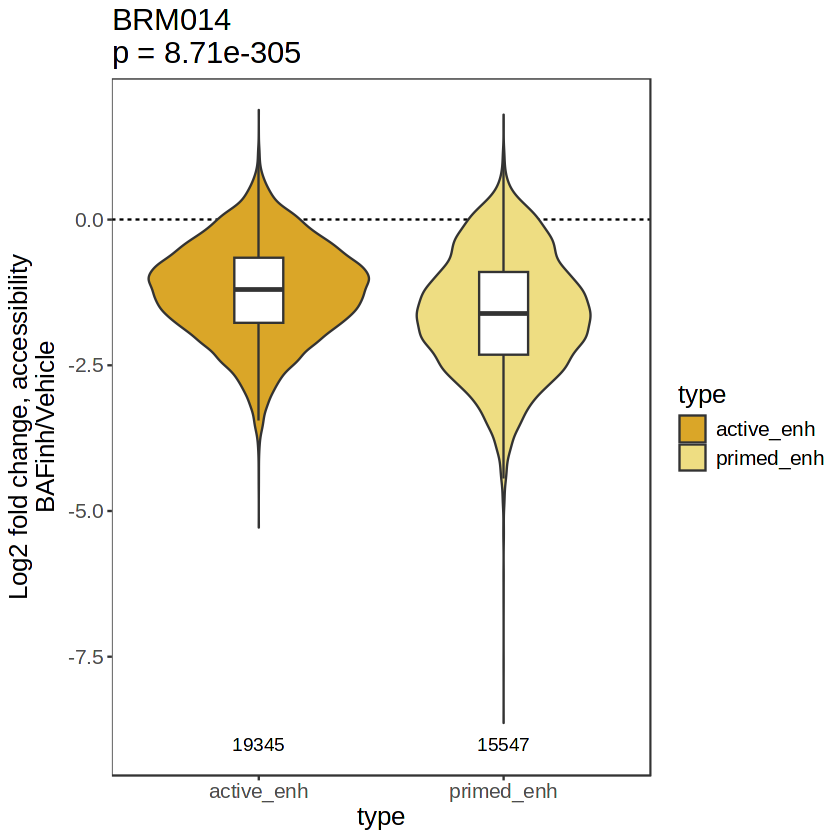

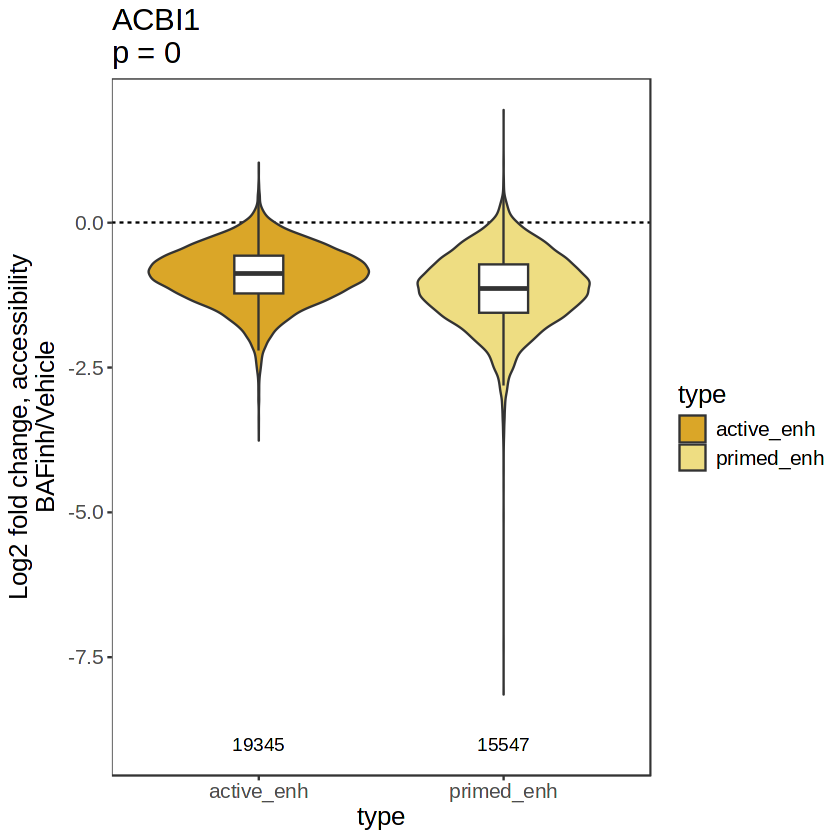

In [3]:
#plot
#p-value from Wilcoxon rank sum test, comparing ATAC-seq log2FCs BAFinh vs Veh in active vs poised enh
p <- wilcox.test(DAR[DAR$type=="active_enh",]$logFC, DAR[DAR$type=="primed_enh",]$logFC)$p.value 
p_brm <- DAR %>% filter(type %in% c("active_enh", "primed_enh")) %>%
    ggplot(aes(x=type,y=logFC, fill=type)) + 
        geom_hline(yintercept=0, linetype=2) + 
        geom_violin() +
        geom_boxplot(width=.2, outlier.shape=NA, fill="white") +
        geom_text(data= DAR %>% filter(type %in% c("active_enh", "primed_enh")) %>% group_by(type) %>% summarize(count=n()), 
                  aes(x=type,y=-9, label=count)) + 
        ggtitle(paste0("BRM014", '\n',"p = ", format(p,digits=3))) + 
        ylab("Log2 fold change, accessibility\nBAFinh/Vehicle") +
        scale_fill_manual(values=c("#daa628", "#eedd82"))
p_brm

p <- wilcox.test(DAR_acbi1[DAR_acbi1$type=="active_enh",]$logFC, DAR_acbi1[DAR_acbi1$type=="primed_enh",]$logFC)$p.value
p_ac <- DAR_acbi1 %>% filter(type %in% c("active_enh", "primed_enh")) %>%
    ggplot(aes(x=type,y=logFC, fill=type)) + 
        geom_hline(yintercept=0, linetype=2) + 
        geom_violin() +
        geom_boxplot(width=.2, outlier.shape=NA, fill="white") +
        geom_text(data= DAR_acbi1 %>% filter(type %in% c("active_enh", "primed_enh")) %>% group_by(type) %>% summarize(count=n()), 
                  aes(x=type,y=-9, label=count)) + 
        ggtitle(paste0("ACBI1", '\n', "p = ", format(p,digits=3))) + 
        ylab("Log2 fold change, accessibility\nBAFinh/Vehicle") +
        scale_fill_manual(values=c("#daa628", "#eedd82")) 
p_ac

# Assemble figure panel

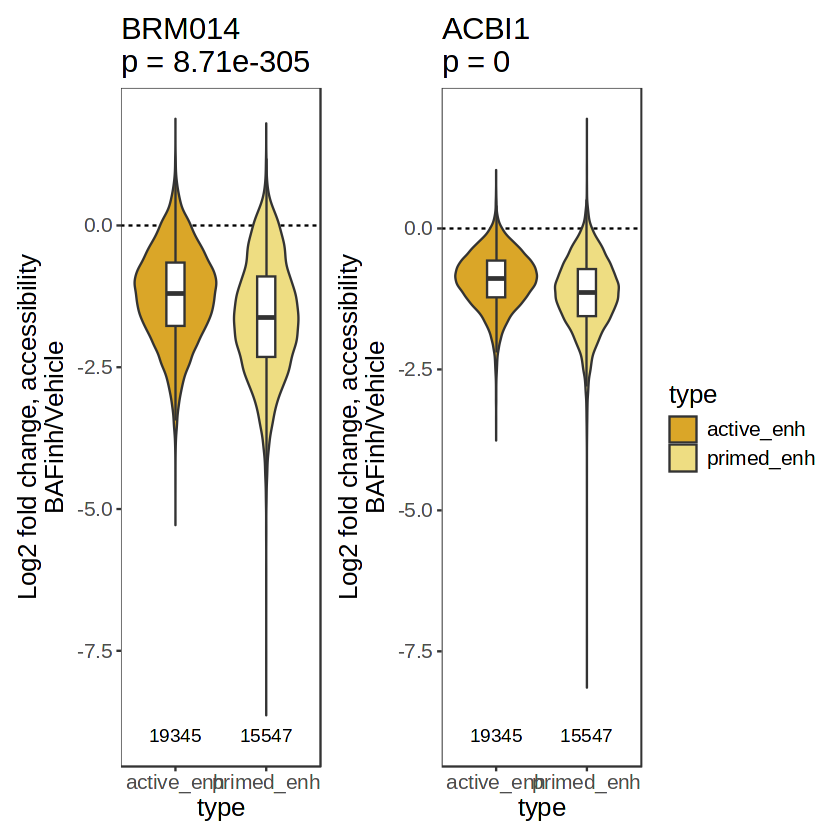

In [4]:
(p_brm | p_ac) + plot_layout(guides="collect") 
ggsave("panel_c_violin.pdf", height=4, width=6)